# **III. Câu hỏi Machine Learning**

### **3.1. Dự đoán ứng dụng đạt ngưỡng phổ biến đại chúng (Installs ≥ 1.000.000)**

**Người thực hiện:** Văn Đình Hiếu

**Câu hỏi:** Chỉ dùng các thuộc tính mô tả sản phẩm và cấu hình kỹ thuật biết trước (không dùng `Reviews`, `Rating`), mô hình học máy phân loại được ứng dụng đạt `Installs` ≥ 1.000.000 tốt hơn baseline ngây thơ bao nhiêu, và đặc trưng nào đóng vai trò quyết định nhất?

**Động lực:** Giúp nhà phát triển độc lập và nhà phát hành ước lượng khả năng một ứng dụng đạt quy mô triệu lượt tải từ danh mục, thể loại, giá, dung lượng và phiên bản Android hỗ trợ, mà không bị đánh lừa bởi các chỉ số chỉ có sau khi ứng dụng đã có người dùng.

#### **1. Bài toán, nhãn và chống rò rỉ dữ liệu**

- **Bài toán:** phân loại nhị phân, `y = 1` nếu cận dưới `Installs` ≥ 1.000.000, ngược lại `y = 0`. Người dùng là nhà phát triển cần đánh giá trước khi hoặc ngay khi phát hành.
- **Đặc trưng dùng:** `Category`, `Genres`, `Content Rating`, `Price`, `Size_MB` kèm `Size_varies`, phiên bản Android tối thiểu (`Android_min`, `Android_varies`) và hai đặc trưng từ tên app (`Name_len`, `Name_words`).
- **Cột bị loại:** `Reviews` (Spearman 0,97 với `Installs`), `Rating` (chỉ có sau khi có người dùng), `Last Updated` và `Current Ver` (phát sinh sau phát hành), `Installs` (nhãn). `App` chỉ dùng làm khóa chia nhóm.
- **`Type` bị bỏ** vì Free khớp hoàn toàn với `Price` = 0 và Paid khớp hoàn toàn với `Price` > 0 (bảng bên dưới), giữ cả hai chỉ lặp thông tin.
- Dùng toàn bộ 10.357 dòng đã tiền xử lý (không loại bản ghi trùng tên), vì việc chia theo nhóm xử lý các dòng cùng tên.

In [1]:
# ---Nạp các thư viện xử lý dữ liệu và trực quan hóa---
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# ---Nạp các công cụ tiền xử lý và xây dựng mô hình---
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    GridSearchCV, GroupKFold, GroupShuffleSplit, cross_val_score
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# ---Nạp các công cụ đánh giá mô hình---
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix,
    f1_score, precision_recall_curve, roc_auc_score, roc_curve
)

# ---Xác định thư mục dự án và nạp mô đun tiền xử lý---
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "raw").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

project_path = str(PROJECT_ROOT.resolve())
if project_path not in sys.path:
    sys.path.insert(0, project_path)

import src.preprocessing as preprocessing

# ---Đọc dữ liệu và áp dụng quy trình tiền xử lý chung---
apps_path = PROJECT_ROOT / "data/raw/googleplaystore.csv"
apps_raw = pd.read_csv(apps_path)
apps, cleaning_report = preprocessing.preprocess_apps(apps_raw)
display(cleaning_report)

# ---Tạo nhãn đạt ít nhất một triệu lượt cài đặt---
apps["y"] = (apps["Installs"] >= 1_000_000).astype(int)
labels_per_app = apps.groupby("App")["y"].nunique()
conflict = (labels_per_app > 1).sum()

print(f"Rows: {len(apps):,}")
print(f"Distinct app names: {apps['App'].nunique():,}")
positive_share = apps["y"].mean()
print(f"Positive class share (>=1M): {positive_share:.3f}")
print(f"App names with conflicting labels: {conflict}")

# ---Kiểm tra thông tin trùng nhau giữa Type và Price---
type_price = apps[["Type", "Price"]].copy()
type_price["Price > 0"] = type_price["Price"] > 0
type_price_counts = type_price.groupby(
    ["Type", "Price > 0"], observed=True
).size()
type_price_counts = type_price_counts.unstack(
    "Price > 0", fill_value=0
)
display(type_price_counts)

,Step,Rows before,Removed,Rows after
0,Remove malformed rows,10841,1,10840
1,Remove exact duplicates,10840,483,10357


Rows: 10,357
Distinct app names: 9,659
Positive class share (>=1M): 0.391
App names with conflicting labels: 6


Price > 0,False,True
Type,,
Free,9592,0
Paid,0,765


Tỷ lệ lớp 1 là 39,1%, không quá lệch nhưng baseline đoán lớp đa số vẫn đạt Accuracy 0,61 mà không phân loại được ứng dụng phổ biến nào. Có 6 tên ứng dụng có nhãn khác nhau giữa các dòng, rất ít nên không ảnh hưởng đáng kể.

In [2]:
# ---Tách phiên bản Android tối thiểu và cờ tùy thiết bị---
android_text = apps["Android Ver"].astype("string")
android_min = android_text.str.extract(r"^(\d+(?:\.\d+)?)")[0]
android_min = android_min.astype(float)
android_varies = (android_text == "Varies with device").astype(float)

# ---Chỉ tạo đặc trưng từ mô tả sản phẩm và cấu hình kỹ thuật---
X = pd.DataFrame({
    "Category": apps["Category"].astype(str),
    "Genres": apps["Genres"].astype(str),
    "Content Rating": apps["Content Rating"].astype(str),
    "Price": apps["Price"],
    "Size_MB": apps["Size_MB"],
    "Size_varies": apps["Size_varies"].astype(float),
    "Android_min": android_min,
    "Android_varies": android_varies,
    "Name_len": apps["App"].str.len(),
    "Name_words": apps["App"].str.split().str.len()
})
y = apps["y"]
groups = apps["App"]

# ---Khai báo các nhóm đặc trưng dùng cho từng mô hình---
CAT_COLS = ["Category", "Genres", "Content Rating"]
NUM_COLS = [
    "Price", "Size_MB", "Size_varies", "Android_min",
    "Android_varies", "Name_len", "Name_words"
]
TECH_COLS = [
    "Size_MB", "Size_varies", "Android_min", "Android_varies",
    "Name_len", "Name_words"
]

print(
    "Excluded: Reviews, Rating, Installs, "
    "Last Updated, Current Ver."
)
print("App is used only as the grouping key.")
print("Type is excluded because it duplicates Price > 0.")
missing_summary = X.isna().sum().rename("Missing").to_frame().T
display(missing_summary)

Excluded: Reviews, Rating, Installs, Last Updated, Current Ver.
App is used only as the grouping key.
Type is excluded because it duplicates Price > 0.


,Category,Genres,Content Rating,Price,Size_MB,Size_varies,Android_min,Android_varies,Name_len,Name_words
Missing,0,0,0,0,1526,0,1223,2,0,0


`Size_MB` có 1.526 giá trị thiếu, đều là nhóm "Varies with device"; `Android_min` có 1.223 giá trị thiếu do "Varies with device" hoặc thiếu phiên bản. Hai nhóm này được điền trung vị trong Pipeline (chỉ học trên train) và đã có cờ `Size_varies`, `Android_varies` đi kèm.

#### **2. Chia dữ liệu theo nhóm**

Nhiều dòng cùng một tên ứng dụng thuộc cùng một thực thể, nên nhóm dùng `GroupShuffleSplit` (80% train, 20% test) với nhóm là `App`. Tập test chỉ dùng để đánh giá cuối cùng.

In [3]:
# ---Chia theo tên ứng dụng để tránh trùng nhóm giữa hai tập---
splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.2, random_state=42
)
for train_idx, test_idx in splitter.split(X, y, groups):
    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]
    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]
    g_train = groups.iloc[train_idx]
    g_test = groups.iloc[test_idx]

# ---Kiểm tra số dòng, số ứng dụng và tỷ lệ lớp---
shared_names = set(g_train) & set(g_test)
print(f"Train rows: {len(X_train):,}")
print(f"Train app names: {g_train.nunique():,}")
print(f"Test rows: {len(X_test):,}; app names: {g_test.nunique():,}")
print(f"Shared app names: {len(shared_names)}")
print(f"Positive class share in train: {y_train.mean():.3f}")
print(f"Positive class share in test: {y_test.mean():.3f}")

Train rows: 8,291
Train app names: 7,727
Test rows: 2,066; app names: 1,932
Shared app names: 0
Positive class share in train: 0.392
Positive class share in test: 0.388


Hai tập không có tên ứng dụng nào chung và tỷ lệ lớp tương đương nhau (0,392 và 0,388).

#### **3. Pipeline, so sánh mô hình và tinh chỉnh**

Mọi bước tiền xử lý nằm trong `Pipeline`: cột số dùng `SimpleImputer(median)` và `StandardScaler`, cột phân loại dùng `OneHotEncoder(min_frequency=20, handle_unknown="ignore")` để gộp thể loại hiếm (`Genres` có 119 giá trị, 57 giá trị dưới 10 dòng). Ba mô hình được so sánh:

1. **Baseline:** `DummyClassifier(strategy="most_frequent")`.
2. **Logistic Regression:** mô hình tuyến tính có điều chuẩn, tinh chỉnh `C`.
3. **HistGradientBoosting:** mô hình phi tuyến, tinh chỉnh `learning_rate`, `max_depth`, `min_samples_leaf`.

Tinh chỉnh bằng `GridSearchCV` với `GroupKFold(5)` theo `App`, chỉ trên tập train, chấm điểm bằng ROC-AUC.

In [4]:
# ---Tạo quy trình tiền xử lý riêng cho cột số và phân loại---
def make_pipe(model, num_cols, cat_cols):
    numeric_steps = [
        ("imp", SimpleImputer(strategy="median")),
        ("sc", StandardScaler())
    ]
    numeric_pipe = Pipeline(numeric_steps)
    transformers = [("num", numeric_pipe, num_cols)]

    if cat_cols:
        encoder = OneHotEncoder(
            handle_unknown="ignore", min_frequency=20,
            sparse_output=False
        )
        transformers.append(("cat", encoder, cat_cols))

    preprocessor = ColumnTransformer(transformers)
    return Pipeline([("prep", preprocessor), ("model", model)])


# ---Khai báo ba mô hình và lưới siêu tham số---
cv = GroupKFold(n_splits=5)
dummy_pipe = make_pipe(
    DummyClassifier(strategy="most_frequent"), NUM_COLS, CAT_COLS
)
logistic_pipe = make_pipe(
    LogisticRegression(max_iter=2000), NUM_COLS, CAT_COLS
)
boosting_pipe = make_pipe(
    HistGradientBoostingClassifier(random_state=42),
    NUM_COLS, CAT_COLS
)
logistic_grid = {"model__C": [0.01, 0.1, 1, 10]}
boosting_grid = {
    "model__learning_rate": [0.03, 0.1],
    "model__max_depth": [3, None],
    "model__min_samples_leaf": [20, 50]
}
searches = {
    "Dummy (most_frequent)": dummy_pipe,
    "Logistic Regression": GridSearchCV(
        logistic_pipe, logistic_grid, cv=cv, scoring="roc_auc"
    ),
    "HistGradientBoosting": GridSearchCV(
        boosting_pipe, boosting_grid, cv=cv, scoring="roc_auc"
    )
}

# ---Chỉ huấn luyện và tinh chỉnh trên tập train---
cv_rows = []
for name, estimator in searches.items():
    if isinstance(estimator, GridSearchCV):
        estimator.fit(X_train, y_train, groups=g_train)
        score = estimator.best_score_
        parameters = estimator.best_params_
    else:
        estimator.fit(X_train, y_train)
        fold_scores = cross_val_score(
            estimator, X_train, y_train, groups=g_train,
            cv=cv, scoring="roc_auc"
        )
        score = fold_scores.mean()
        parameters = "-"

    cv_rows.append({
        "Model": name,
        "Train CV ROC-AUC": score,
        "Best parameters": parameters
    })
cv_scores = pd.DataFrame(cv_rows).set_index("Model")
with pd.option_context("display.max_colwidth", None):
    display(cv_scores.round(4))

# ---Chọn mô hình bằng điểm kiểm định chéo, không dùng điểm test---
model_names = ["Logistic Regression", "HistGradientBoosting"]
best_name = cv_scores.loc[model_names, "Train CV ROC-AUC"].idxmax()
best_est = searches[best_name]
print(f"Best model selected by train CV: {best_name}")

# ---Huấn luyện đối chứng kỹ thuật trước khi đánh giá tập test---
hgb_params = searches["HistGradientBoosting"].best_params_
tech = make_pipe(
    HistGradientBoostingClassifier(random_state=42), TECH_COLS, []
)
tech.set_params(**hgb_params)
tech.fit(X_train[TECH_COLS], y_train)

,Train CV ROC-AUC,Best parameters
Model,,
Dummy (most_frequent),0.5000,-
Logistic Regression,0.8343,{'model__C': 10}
HistGradientBoosting,0.8546,"{'model__learning_rate': 0.1, 'model__max_depth': None, 'model__min_samples_leaf': 20}"


Best model selected by train CV: HistGradientBoosting


Hai mô hình đều vượt baseline (ROC-AUC 0,50) rõ rệt khi kiểm định chéo theo nhóm: Logistic Regression 0,834 và HistGradientBoosting 0,855.

#### **4. Đánh giá trên tập test**

Nhóm báo cáo ROC-AUC (không phụ thuộc ngưỡng), PR-AUC và F1 (nhấn vào lớp phổ biến). Accuracy chỉ để đối chiếu: baseline đạt 0,61 nhưng F1 bằng 0 vì không bao giờ dự đoán lớp 1, nên Accuracy một mình dễ gây hiểu lầm khi lớp 0 chiếm đa số.

In [5]:
# ---Đánh giá mỗi mô hình đã huấn luyện trên tập test---
proba = {}
pred = {}
rows = []
for name, estimator in searches.items():
    probabilities = estimator.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)
    proba[name] = probabilities
    pred[name] = predictions
    rows.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "PR-AUC": average_precision_score(y_test, probabilities),
        "F1": f1_score(y_test, predictions),
        "Accuracy": accuracy_score(y_test, predictions)
    })
test_scores = pd.DataFrame(rows).set_index("Model")
display(test_scores.round(4))
print(f"Positive class share in test: {y_test.mean():.3f}")

# ---Lưu kết quả đối chứng để so sánh ở phần giải thích mô hình---
p_tech = tech.predict_proba(X_test[TECH_COLS])[:, 1]
tech_roc_auc = roc_auc_score(y_test, p_tech)
tech_pr_auc = average_precision_score(y_test, p_tech)

,ROC-AUC,PR-AUC,F1,Accuracy
Model,,,,
Dummy (most_frequent),0.5000,0.3877,0.0000,0.6123
Logistic Regression,0.8431,0.7704,0.6699,0.7711
HistGradientBoosting,0.8574,0.7904,0.7068,0.7856


Positive class share in test: 0.388


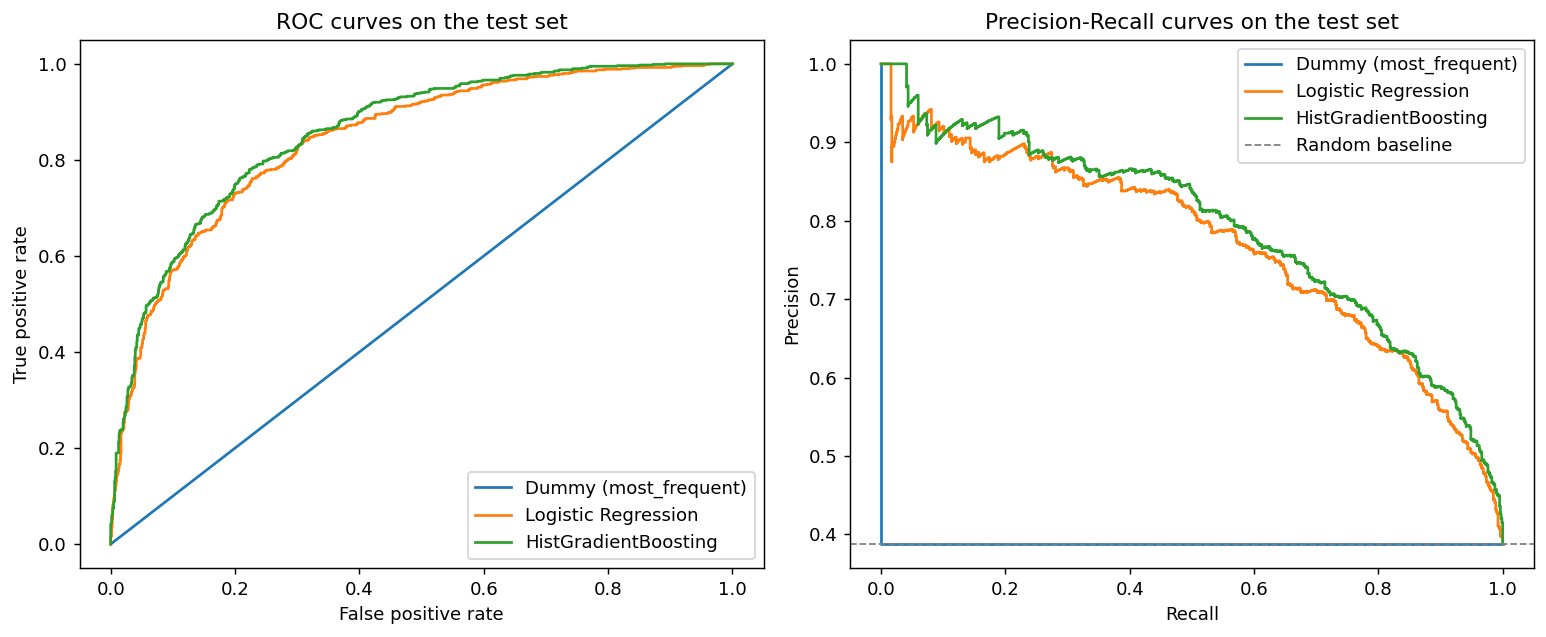

In [6]:
# ---Vẽ đường ROC và đường Precision-Recall từ xác suất đã lưu---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, probabilities in proba.items():
    false_positive, true_positive, thresholds = roc_curve(
        y_test, probabilities
    )
    precision, recall, thresholds = precision_recall_curve(
        y_test, probabilities
    )
    axes[0].plot(false_positive, true_positive, label=name)
    axes[1].step(recall, precision, where="post", label=name)

axes[0].set_title("ROC curves on the test set")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].legend()
axes[1].set_title("Precision-Recall curves on the test set")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].axhline(
    y_test.mean(), color="gray", linestyle="--",
    linewidth=1, label="Random baseline"
)
axes[1].legend()
plt.tight_layout()
plt.show()

- HistGradientBoosting đạt ROC-AUC **0,857**, PR-AUC **0,790**, F1 **0,707**; Logistic Regression đạt 0,843, 0,770 và 0,670. Baseline có ROC-AUC 0,500, PR-AUC 0,388 và F1 0.
- So với baseline, HistGradientBoosting tăng ROC-AUC thêm **0,357**, PR-AUC thêm **0,403** (gấp khoảng 2 lần mức ngẫu nhiên 0,388) và F1 thêm 0,707.
- Mô hình phi tuyến hơn Logistic Regression khoảng 0,014 ROC-AUC, nên phần lớn tín hiệu đã có tính tuyến tính theo đặc trưng, mô hình phi tuyến chỉ cải thiện thêm một ít.

#### **5. Phân tích lỗi**

Nhóm lấy mô hình có ROC-AUC kiểm định chéo cao nhất trên tập train, xem ma trận nhầm lẫn, tỷ lệ dương tính giả (FP rate, tính trên các app thật sự < 1M) và âm tính giả (FN rate, tính trên các app thật sự ≥ 1M) theo nhóm kích thước và `Category` (chỉ các danh mục có từ 40 dòng test), rồi liệt kê các app sai nặng nhất.

In [7]:
# ---Dùng mô hình đã chọn từ kiểm định chéo để phân tích lỗi---
error_cols = [
    "App", "Category", "Size_MB", "Size_varies", "Price", "Installs"
]
err = apps.loc[X_test.index, error_cols].copy()
err["y"] = y_test.to_numpy()
err["proba"] = proba[best_name]
err["pred"] = pred[best_name]
err["FP"] = (err["pred"] == 1) & (err["y"] == 0)
err["FN"] = (err["pred"] == 0) & (err["y"] == 1)

# ---Chia nhóm kích thước và giữ riêng kích thước tùy thiết bị---
size_labels = ["(0, 5] MB", "(5, 20] MB", "(20, 50] MB", ">50 MB"]
err["Size_group"] = pd.cut(
    err["Size_MB"], [0, 5, 20, 50, np.inf], labels=size_labels
)
err["Size_group"] = err["Size_group"].cat.add_categories("Varies")
err["Size_group"] = err["Size_group"].fillna("Varies")

# ---Hiển thị ma trận nhầm lẫn---
print(f"Best model selected by train CV: {best_name}")
confusion = confusion_matrix(y_test, err["pred"])
confusion_table = pd.DataFrame(
    confusion, index=["Actual 0", "Actual 1"],
    columns=["Predicted 0", "Predicted 1"]
)
display(confusion_table)


# ---Tính tỷ lệ lỗi với mẫu số riêng cho từng lớp thực tế---
def error_rates(column, min_n):
    table = err.groupby(column, observed=True).agg(
        n=("y", "size"),
        FP_count=("FP", "sum"),
        FN_count=("FN", "sum"),
        n_pos=("y", "sum")
    )
    table["n_neg"] = table["n"] - table["n_pos"]
    table["FP rate"] = table["FP_count"] / table["n_neg"]
    table["FN rate"] = table["FN_count"] / table["n_pos"]
    table = table.loc[table["n"] >= min_n]
    return table[["n", "FP rate", "FN rate"]].round(3)


display(error_rates("Size_group", 1))
category_errors = error_rates("Category", 40)
display(category_errors.sort_values("n", ascending=False))

Best model selected by train CV: HistGradientBoosting


,Predicted 0,Predicted 1
Actual 0,1089,176
Actual 1,267,534


,n,FP rate,FN rate
Size_group,,,
"(0, 5] MB",476,0.015,0.896
"(5, 20] MB",624,0.101,0.641
"(20, 50] MB",459,0.195,0.380
>50 MB,226,0.412,0.114
Varies,281,0.694,0.041


,n,FP rate,FN rate
Category,,,
FAMILY,409,0.128,0.352
GAME,228,0.380,0.121
TOOLS,181,0.066,0.322
BUSINESS,94,0.037,0.417
MEDICAL,86,0.000,1.000
SPORTS,83,0.067,0.526
PRODUCTIVITY,78,0.179,0.436
FINANCE,71,0.102,0.364
LIFESTYLE,70,0.098,0.667


- Ở ngưỡng 0,5, mô hình bỏ sót 267 app phổ biến (FN) và gán nhầm 176 app chưa phổ biến (FP).
- **Theo kích thước:** lỗi phụ thuộc mạnh vào `Size`. App ≤5MB bị bỏ sót 89,6% (FN rate 0,896) còn FP gần như 0. App "Varies with device" có FP rate 0,694 và FN rate chỉ 0,041. Nghĩa là mô hình đang coi dung lượng lớn hoặc không xác định là dấu hiệu phổ biến, nhóm nhỏ gần như bị mặc định là không phổ biến.
- **Theo danh mục:** `GAME` (FP 0,380) và `SHOPPING` (0,381) bị dự đoán thừa, `COMMUNICATION` và `PHOTOGRAPHY` cũng cao (lần lượt 0,257 và 0,278). `MEDICAL` có FN rate 1,000 (mọi app phổ biến đều bị bỏ sót, chỉ vài app), `PERSONALIZATION` 0,684, `BOOKS_AND_REFERENCE` 0,636.

In [8]:
# ---Xem các dự đoán sai có xác suất tự tin nhất---
cols = ["App", "Category", "Size_MB", "Price", "Installs", "proba"]
false_positives = err.loc[err["FP"]]
false_negatives = err.loc[err["FN"]]
false_positives = false_positives.sort_values(
    "proba", ascending=False, kind="stable"
)
false_negatives = false_negatives.sort_values("proba", kind="stable")

print("Top 10 false positives with the highest probabilities:")
display(false_positives[cols].head(10).round(3))
print("Top 10 false negatives with the lowest probabilities:")
display(false_negatives[cols].head(10).round(3))

Top 10 false positives with the highest probabilities:


,App,Category,Size_MB,Price,Installs,proba
9563,Ex Explorer : Dual view exproler / file manager,TOOLS,NaN,0.0,50000,0.952
825,Universal Kids,ENTERTAINMENT,21.0,0.0,500000,0.952
790,Harkins Theatres,ENTERTAINMENT,12.0,0.0,100000,0.933
1843,Fruit Cube Blast,FAMILY,80.0,0.0,500000,0.931
7650,SuperBikers 2,GAME,NaN,0.0,500000,0.926
822,CW Seed,ENTERTAINMENT,13.0,0.0,500000,0.924
2645,"Hole19: Golf GPS App, Rangefinder & Scorecard",SPORTS,NaN,0.0,100000,0.917
3421,"Dynavix - Navigation, Maps, Traffic data & Cam...",MAPS_AND_NAVIGATION,NaN,0.0,50000,0.916
803,Acorn TV: World-class TV from Britain and Beyond,ENTERTAINMENT,23.0,0.0,50000,0.897
8458,DV-4036 by Somikon,PHOTOGRAPHY,44.0,0.0,1000,0.890


Top 10 false negatives with the lowest probabilities:


,App,Category,Size_MB,Price,Installs,proba
1391,H Pack,LIFESTYLE,1.7,0.00,1000000,0.019
4876,Ayat - Al Quran,FAMILY,8.5,0.00,5000000,0.024
861,Fever,EVENTS,12.0,0.00,1000000,0.031
5034,True Skate,SPORTS,73.0,1.99,1000000,0.039
3883,French to English Speaking - Apprendre l' Anglais,FAMILY,13.0,0.00,1000000,0.051
2988,HD Widgets,PERSONALIZATION,26.0,0.99,1000000,0.053
6452,HD Widgets,PERSONALIZATION,26.0,0.99,1000000,0.053
2532,Facetune - For Free,PHOTOGRAPHY,48.0,5.99,1000000,0.056
1983,Minecraft,FAMILY,NaN,6.99,10000000,0.061
3893,Minecraft,FAMILY,NaN,6.99,10000000,0.061


- **FP nặng:** nhiều app giải trí hoặc thuộc thương hiệu (`Universal Kids`, `Harkins Theatres`, `CW Seed`, `Acorn TV`) có đặc trưng giống app lớn (miễn phí, danh mục giải trí, dung lượng vừa) nhưng chỉ có 50K–500K lượt cài. Một số có `Size_MB` thiếu (Varies) nên bị mô hình coi như app lớn.
- **FN nặng:** các app nhỏ hoặc có trả phí nhưng cực phổ biến, ví dụ `Minecraft` (6,99 USD, 10 triệu), `HD Widgets` (0,99 USD), `True Skate` (1,99 USD), cùng các app nhẹ như `Ayat - Al Quran` (8,5 MB) và `H Pack` (1,7 MB). Mức độ phổ biến có thể gắn với thương hiệu hoặc nhu cầu cộng đồng, nhưng các yếu tố này chưa được đo trực tiếp trong bộ đặc trưng.

#### **6. Giải thích mô hình bằng permutation importance**

Nhóm xáo trộn từng cột gốc trong tập test (20 lần) rồi đo mức giảm ROC-AUC của toàn Pipeline, nên các cột one-hot của `Category` hoặc `Genres` được tính chung thành một đặc trưng. Ngoài ra, nhóm huấn luyện một mô hình chỉ dùng đặc trưng kỹ thuật, với cùng siêu tham số, để biết đóng góp của chúng khi không có thông tin danh mục và giá.

,mean,std
Category,0.0831,0.0056
Size_MB,0.0802,0.0049
Price,0.0591,0.0073
Name_len,0.0420,0.0047
Genres,0.0256,0.0030
Size_varies,0.0192,0.0032
Name_words,0.0111,0.0020
Android_varies,0.0102,0.0020
Android_min,0.0052,0.0018
Content Rating,0.0029,0.0011


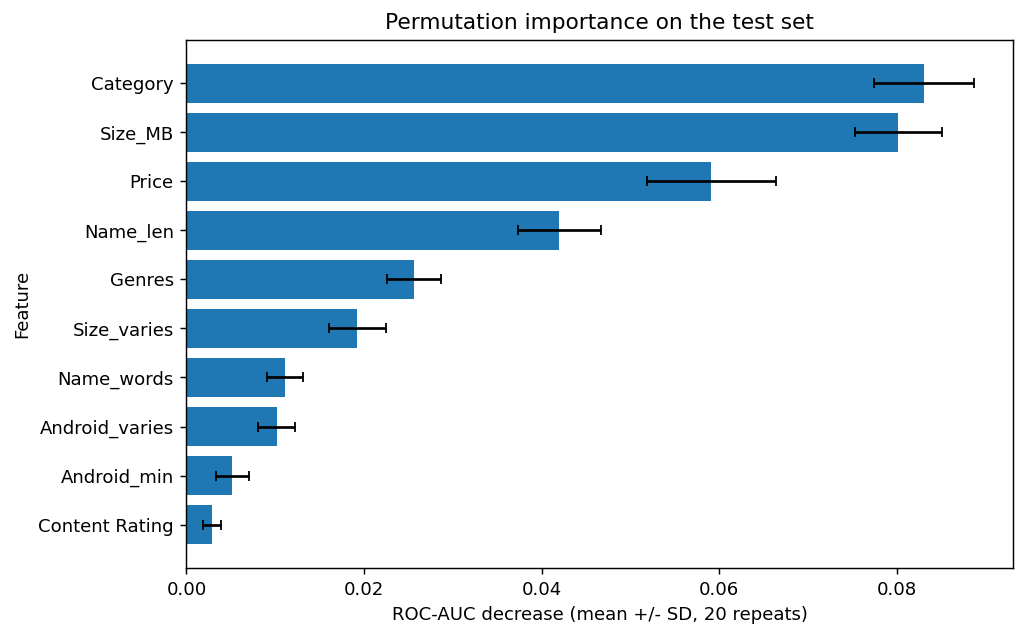

In [9]:
# ---Đo mức giảm ROC-AUC khi xáo trộn từng cột đầu vào---
perm = permutation_importance(
    best_est, X_test, y_test, scoring="roc_auc",
    n_repeats=20, random_state=42
)
imp = pd.DataFrame({
    "mean": perm.importances_mean,
    "std": perm.importances_std
}, index=X_test.columns)
imp = imp.sort_values("mean")
display(imp.sort_values("mean", ascending=False).round(4))

# ---Vẽ mức đóng góp cùng độ lệch chuẩn qua hai mươi lần---
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index, imp["mean"], xerr=imp["std"], capsize=3)
ax.set_title("Permutation importance on the test set")
ax.set_xlabel("ROC-AUC decrease (mean +/- SD, 20 repeats)")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

In [10]:
# ---So sánh kết quả đã lưu của mô hình đối chứng và đầy đủ---
full_roc_auc = test_scores.loc["HistGradientBoosting", "ROC-AUC"]
full_pr_auc = test_scores.loc["HistGradientBoosting", "PR-AUC"]
feature_comparison = pd.DataFrame([
    {
        "Features": "Technical only",
        "ROC-AUC": tech_roc_auc,
        "PR-AUC": tech_pr_auc
    },
    {
        "Features": "All features (HistGradientBoosting)",
        "ROC-AUC": full_roc_auc,
        "PR-AUC": full_pr_auc
    }
])
display(feature_comparison.round(4))

,Features,ROC-AUC,PR-AUC
0,Technical only,0.7697,0.6823
1,All features (HistGradientBoosting),0.8574,0.7904


- Xếp hạng đóng góp: `Category` (giảm 0,083 ROC-AUC), `Size_MB` (0,080), `Price` (0,059), `Name_len` (0,042), `Genres` (0,026), `Size_varies` (0,019). `Content Rating` và `Android_min` đóng góp nhỏ (lần lượt khoảng 0,003 và 0,005); `Android_varies` khoảng 0,010.
- Nếu chỉ dùng đặc trưng kỹ thuật (kích thước, Android, tên app), ROC-AUC vẫn đạt **0,770**, PR-AUC **0,682**, cao hơn hẳn baseline nhưng thấp hơn mô hình đầy đủ (0,857). Vậy các đặc trưng kỹ thuật đóng góp phần lớn, còn danh mục và giá bổ sung thêm khoảng 0,09 ROC-AUC.
- `Name_len` đóng góp khá lớn, nhưng không nên diễn giải nhân quả: tên ngắn thường là thương hiệu nổi tiếng, nên đây là dấu hiệu của thương hiệu hơn là lựa chọn thiết kế.

#### **7. Trả lời câu hỏi và giới hạn**

**Trả lời:** Chỉ từ thông tin sản phẩm và cấu hình kỹ thuật, mô hình HistGradientBoosting đạt ROC-AUC 0,857, PR-AUC 0,790 và F1 0,707 trên tập test chia theo `App`. Baseline đoán lớp đa số đạt ROC-AUC 0,500, PR-AUC 0,388 và F1 bằng 0, nên mô hình cao hơn 0,357 ROC-AUC và gấp khoảng 2 lần PR-AUC. Quyết định nhất là `Category`, `Size_MB` và `Price`; app miễn phí, thuộc danh mục như `GAME`, dung lượng lớn hoặc "Varies with device" có xác suất đạt triệu lượt tải cao hơn. Phiên bản Android và `Content Rating` gần như không đóng góp.

**Giới hạn:**
- Dữ liệu là ảnh chụp một thời điểm (2018), nên `Size`, tên và `Android Ver` có thể đã thay đổi sau khi ứng dụng có người dùng; "biết trước" chỉ là xấp xỉ.
- Mô hình bỏ sót app phổ biến nhờ thương hiệu hoặc cộng đồng (`Minecraft`, app tôn giáo) và đoán thừa app dung lượng lớn nhưng ít người cài. Dung lượng nhỏ bị mô hình mặc định là không phổ biến (FN 89,6% ở nhóm ≤5MB).
- Kết quả là mối liên hệ dự báo, không phải quan hệ nhân quả: tăng dung lượng hoặc đổi tên app không làm tăng lượt cài.
- Ngưỡng 0,5 và ngưỡng 1 triệu là lựa chọn của nhóm; tập test chỉ có 2.066 dòng nên các tỷ lệ lỗi theo danh mục nhỏ chưa ổn định (ví dụ `MEDICAL`).